# 03 — Evaluation & Grad-CAM

Final, unbiased evaluation of the best checkpoint from `02` on the **test set** (never used so far),
then error analysis and Grad-CAM to check what the model looks at.

In [1]:
from pathlib import Path
import sys
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch.utils.data import DataLoader

ROOT = Path("..")
sys.path.insert(0, str(ROOT.resolve()))

%load_ext autoreload
%autoreload 2

from src.data import CLASSES, BrainMRIDataset, get_transforms
from src.model import load_checkpoint
from src.gradcam import GradCAM

SEED = 42
torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(device)

cuda


In [2]:
CKPT_PATH = ROOT / "models" / "resnet18_best.pt"

model, ckpt = load_checkpoint(CKPT_PATH, device)
assert ckpt["classes"] == CLASSES, "classes in checkpoint differ from src/data.py"
print(f"{ckpt['model_name']} from epoch {ckpt['epoch']}, val macro-F1 {ckpt['val_metrics']['macro_f1']:.4f}")

test_df = pd.read_csv(ROOT / "splits" / "test.csv")
test_ds = BrainMRIDataset(test_df, ROOT, get_transforms(train=False, img_size=ckpt["img_size"]))
test_loader = DataLoader(test_ds, batch_size=32, shuffle=False, num_workers=0)
print(f"test: {len(test_ds)} images")

resnet18.a1_in1k from epoch 14, val macro-F1 0.9830
test: 903 images


In [3]:
@torch.no_grad()
def predict(model, loader):
    """Class probabilities and true labels, in the same order as the dataset."""
    device = next(model.parameters()).device
    model.eval()
    all_probs, all_labels = [], []
    for xb, yb in loader:
        logits = model(xb.to(device))
        all_probs.append(torch.softmax(logits, dim=1).cpu())
        all_labels.append(yb)
    return torch.cat(all_probs).numpy(), torch.cat(all_labels).numpy()


probs, labels = predict(model, test_loader)
preds = probs.argmax(axis=1)

results = test_df.copy()
results["true"] = labels
results["pred"] = preds
results["pred_label"] = [CLASSES[i] for i in preds]
results["confidence"] = probs.max(axis=1)
results["correct"] = results["true"] == results["pred"]

results.head()

,path,label,true,pred,pred_label,confidence,correct
0,data/raw/Training/notumor/Tr-no_295.jpg,notumor,2,2,notumor,0.954191,True
1,data/raw/Training/notumor/Tr-no_1186.jpg,notumor,2,2,notumor,0.999186,True
2,data/raw/Testing/glioma/Te-gl_220.jpg,glioma,0,0,glioma,0.999467,True
3,data/raw/Training/pituitary/Tr-pi_1036.jpg,pituitary,3,3,pituitary,0.999995,True
4,data/raw/Testing/glioma/Te-gl_207.jpg,glioma,0,0,glioma,0.999972,True


              precision    recall  f1-score   support

      glioma      0.992     0.955     0.973       266
  meningioma      0.944     0.991     0.967       222
     notumor      0.980     0.980     0.980       153
   pituitary      0.992     0.989     0.990       262

    accuracy                          0.978       903
   macro avg      0.977     0.979     0.978       903
weighted avg      0.978     0.978     0.978       903

Test macro-F1: 0.9778  (val was 0.9830)


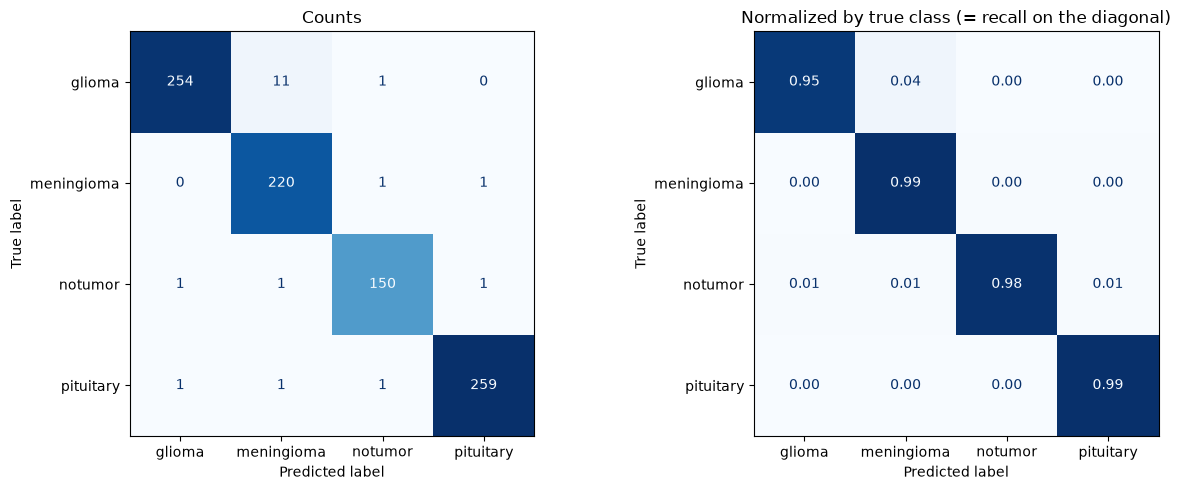

In [4]:
from sklearn.metrics import classification_report, f1_score, ConfusionMatrixDisplay

print(classification_report(labels, preds, target_names=CLASSES, digits=3))
print(f"Test macro-F1: {f1_score(labels, preds, average='macro'):.4f}  "
      f"(val was {ckpt['val_metrics']['macro_f1']:.4f})")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
ConfusionMatrixDisplay.from_predictions(labels, preds, display_labels=CLASSES,
                                        cmap="Blues", colorbar=False, ax=axes[0])
axes[0].set_title("Counts")
ConfusionMatrixDisplay.from_predictions(labels, preds, display_labels=CLASSES, normalize="true",
                                        values_format=".2f", cmap="Blues", colorbar=False, ax=axes[1])
axes[1].set_title("Normalized by true class (= recall on the diagonal)")
plt.tight_layout()
plt.show()

### Observations: test results

- **Test macro-F1 0.978** (val 0.983): slightly lower as expected (val score was the max over epochs), so the validation estimate was reliable.
- 20 errors / 903 images. **11 of 20 are glioma → meningioma**: lowest glioma recall (0.955)
  and lowest meningioma precision (0.944). Plausible clinically (peripheral gliomas vs. irregular meningiomas)
  and possibly partly label noise (cf. `Te-gl_68.jpg` in EDA).
- **3 tumors predicted as notumor** (1 per tumor class): the most harmful error type (missed tumor), to be inspected.
- notumor recall 0.98: so far no sign of the class being "too easy" — Grad-CAM will tell whether it is right for the right reasons.

## Error analysis

Which images are misclassified, how confident the model was, and whether errors cluster somewhere.

20 errors out of 903

label       pred_label
glioma      meningioma    11
            notumor        1
meningioma  notumor        1
            pituitary      1
notumor     glioma         1
            meningioma     1
            pituitary      1
pituitary   glioma         1
            meningioma     1
            notumor        1
Name: count, dtype: int64


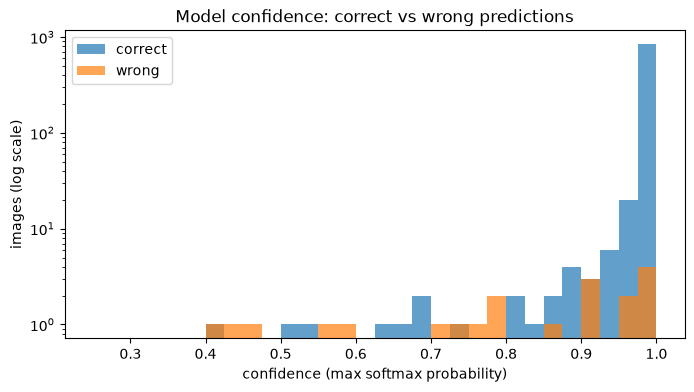

In [5]:
errors = results[~results["correct"]].sort_values("confidence", ascending=False)
print(f"{len(errors)} errors out of {len(results)}\n")
print(errors.groupby(["label", "pred_label"]).size().rename("count").sort_values(ascending=False))

bins = np.linspace(0.25, 1, 31)
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(results.loc[results["correct"], "confidence"], bins=bins, alpha=0.7, label="correct", log=True)
ax.hist(errors["confidence"], bins=bins, alpha=0.7, label="wrong", log=True)
ax.set_xlabel("confidence (max softmax probability)")
ax.set_ylabel("images (log scale)")
ax.set_title("Model confidence: correct vs wrong predictions")
ax.legend()
plt.show()

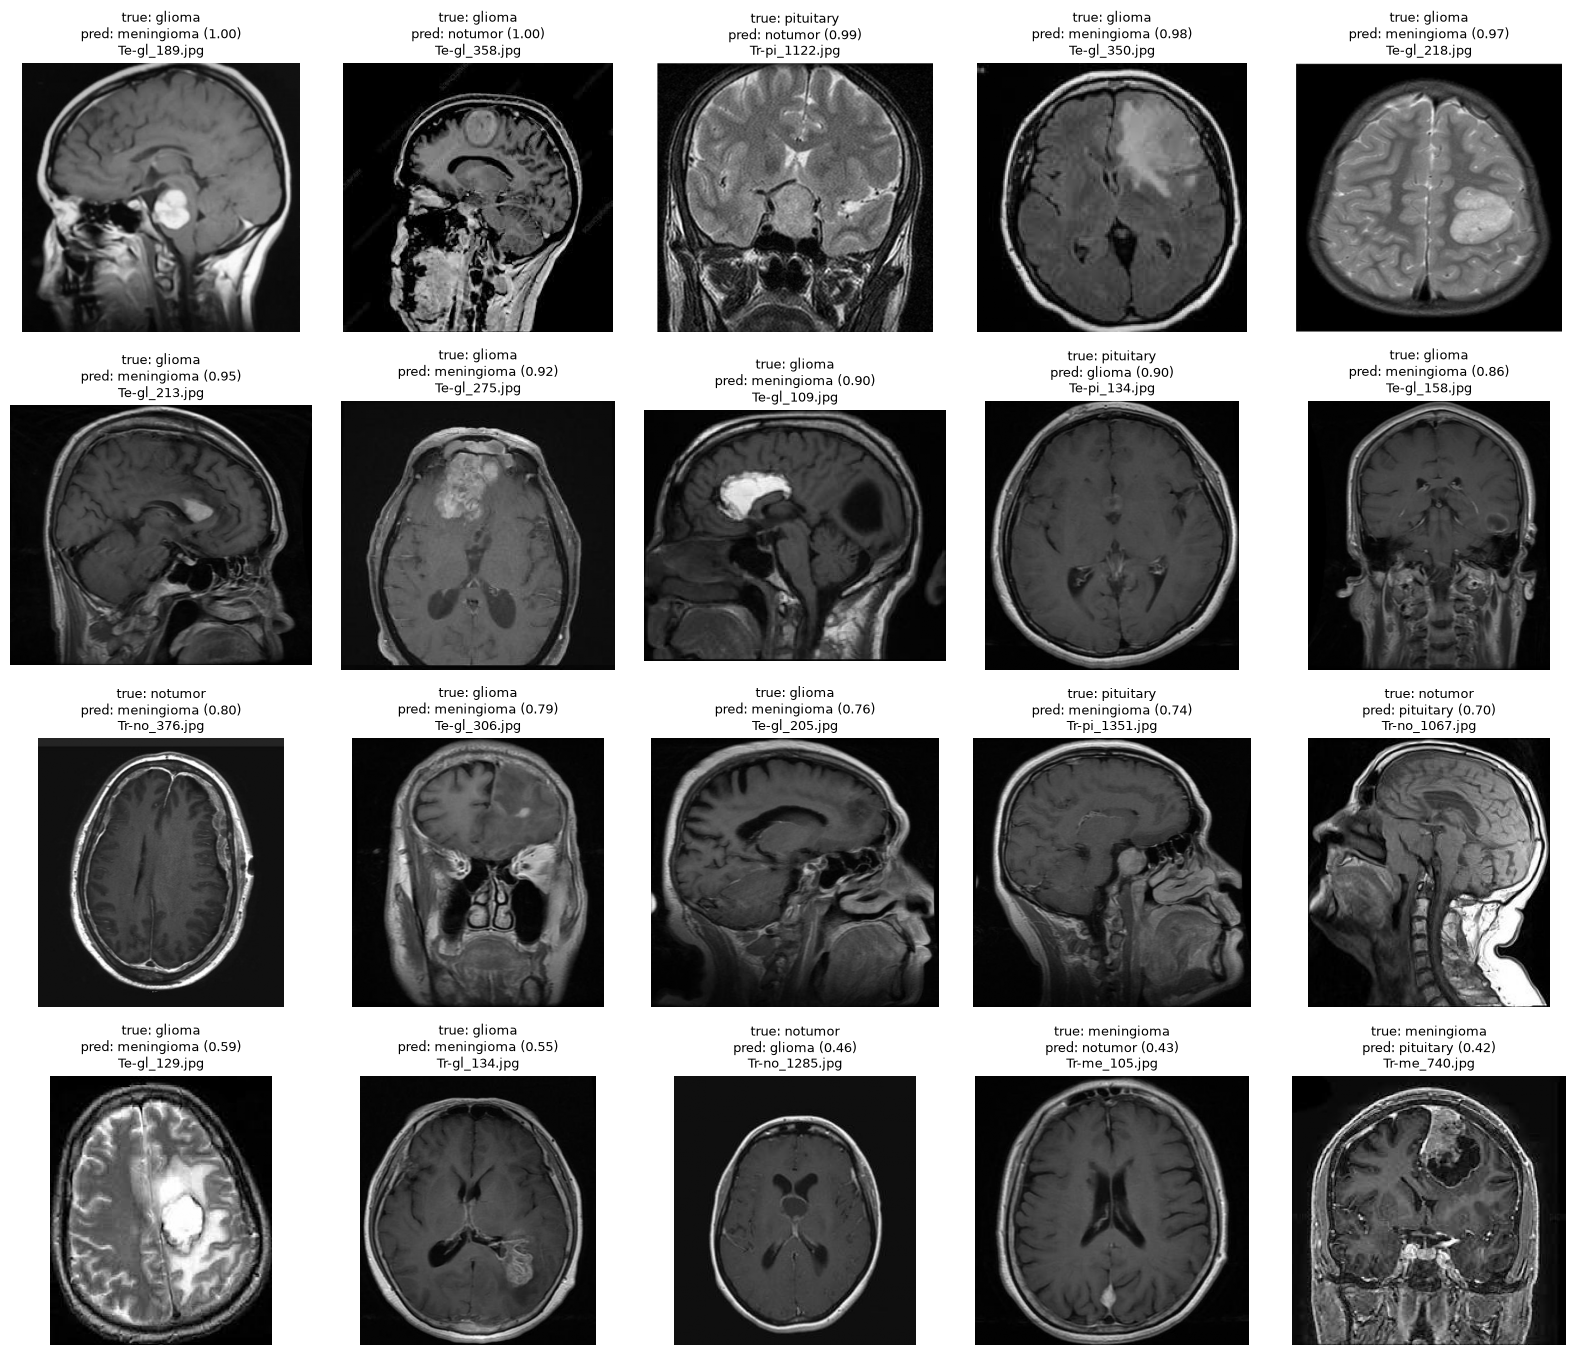

In [6]:
from PIL import Image
from src.data import crop_black_borders

n_cols = 5
n_rows = int(np.ceil(len(errors) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(3.2 * n_cols, 3.4 * n_rows))
for ax in axes.flat:
    ax.axis("off")

for ax, (_, row) in zip(axes.flat, errors.iterrows()):
    with Image.open(ROOT / row["path"]) as img:
        ax.imshow(crop_black_borders(img.convert("L")), cmap="gray")
    ax.set_title(f'true: {row["label"]}\npred: {row["pred_label"]} ({row["confidence"]:.2f})\n'
                 f'{Path(row["path"]).name}', fontsize=9)

plt.tight_layout()
plt.show()

In [7]:
results["origin"] = results["path"].str.split("/").str[2]   # "Training" or "Testing" in the original Kaggle split

results.groupby(["label", "origin"])["correct"].agg(
    n="size",
    errors=lambda s: (~s).sum(),
    acc="mean",
).round(3)

n  errors    acc
label      origin                      
glioma     Testing    63      11  0.825
           Training  203       1  0.995
meningioma Testing    40       0  1.000
           Training  182       2  0.989
notumor    Testing    12       0  1.000
           Training  141       3  0.979
pituitary  Testing    64       1  0.984
           Training  198       2  0.990

Test macro-F1: 0.9778  95% CI [0.9676, 0.9869]


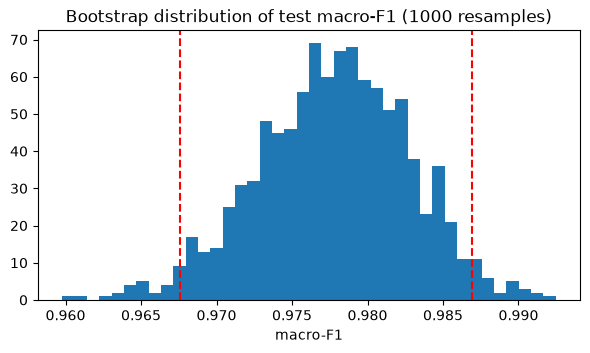

In [8]:
from sklearn.metrics import f1_score

rng = np.random.default_rng(SEED)
n = len(labels)
boot_f1 = []
for _ in range(1000):
    idx = rng.integers(0, n, size=n)        # resample the test set with replacement
    boot_f1.append(f1_score(labels[idx], preds[idx], average="macro"))
boot_f1 = np.array(boot_f1)

low, high = np.percentile(boot_f1, [2.5, 97.5])
print(f"Test macro-F1: {f1_score(labels, preds, average='macro'):.4f}  95% CI [{low:.4f}, {high:.4f}]")

plt.figure(figsize=(7, 3.5))
plt.hist(boot_f1, bins=40)
plt.axvline(low, color="red", linestyle="--")
plt.axvline(high, color="red", linestyle="--")
plt.title("Bootstrap distribution of test macro-F1 (1000 resamples)")
plt.xlabel("macro-F1")
plt.show()

### Observations: error analysis

- **Overconfidence**: ~half of the errors have confidence > 0.9 → softmax probability is not a reliable
  uncertainty measure; the app must not present it as such.
- **Errors cluster in one source folder**: glioma images from the original Kaggle `Testing/` folder have
  accuracy **0.825** (11/63 wrong) vs **0.995** for glioma from `Training/`; every other class/origin is ≥ 0.98.
- Consistent with the EDA label conflict (`Te-gl_68.jpg`, same folder). Likely causes: **label noise**
  (some "gliomas" look like textbook meningiomas, e.g. `Te-gl_189`, `Te-gl_109`) and **under-represented
  sequences** (several T2/FLAIR gliomas). Not a clinical judgement.
- Not fixed on purpose: changing data or model after looking at the test set would bias the test estimate.
  → Reported as a dataset limitation.
- **Test macro-F1 0.978, 95% bootstrap CI [0.968, 0.987]**: val (0.983) lies inside → no evidence of a real gap.

## Grad-CAM

Which regions of the image drive the prediction? Heatmaps on the last convolutional block (`layer4`, 7×7 grid).
Goal: check whether the model looks at the tumor or at shortcuts (framing, global style — see EDA and `02`).

In [9]:
# GradCAM lives in src/gradcam.py (shared with the app). How it works:
#   forward hook  -> saves the 512 feature maps (7x7) of layer4
#   tensor hook   -> saves their gradients w.r.t. the class score during backward
#   cam = ReLU(sum over channels of mean(gradient) * feature map), upsampled to 224x224 and scaled to [0, 1]
gradcam = GradCAM(model, model.layer4)

In [10]:
def to_display(x):
    """Tensor (C, H, W), normalized -> array (H, W, C) in [0, 1] for imshow."""
    x = x.permute(1, 2, 0)
    return (x - x.min()) / (x.max() - x.min())


def show_gradcam(rows, title):
    """Model input (top) and Grad-CAM overlay (bottom) for each row of `results`."""
    n = len(rows)
    fig, axes = plt.subplots(2, n, figsize=(3 * n, 6.4))
    axes = np.array(axes).reshape(2, n)
    for j, (idx, row) in enumerate(rows.iterrows()):
        x, _ = test_ds[idx]
        cam, cls, p = gradcam(x)
        img = to_display(x).numpy()

        axes[0, j].imshow(img)
        axes[0, j].set_title(f'{Path(row["path"]).name}\ntrue: {row["label"]}\n'
                             f'pred: {CLASSES[cls]} ({p[cls]:.2f})', fontsize=9)
        axes[1, j].imshow(img)
        axes[1, j].imshow(cam, cmap="jet", alpha=0.4)
        for ax in axes[:, j]:
            ax.axis("off")
    plt.suptitle(title)
    plt.tight_layout()
    plt.show()

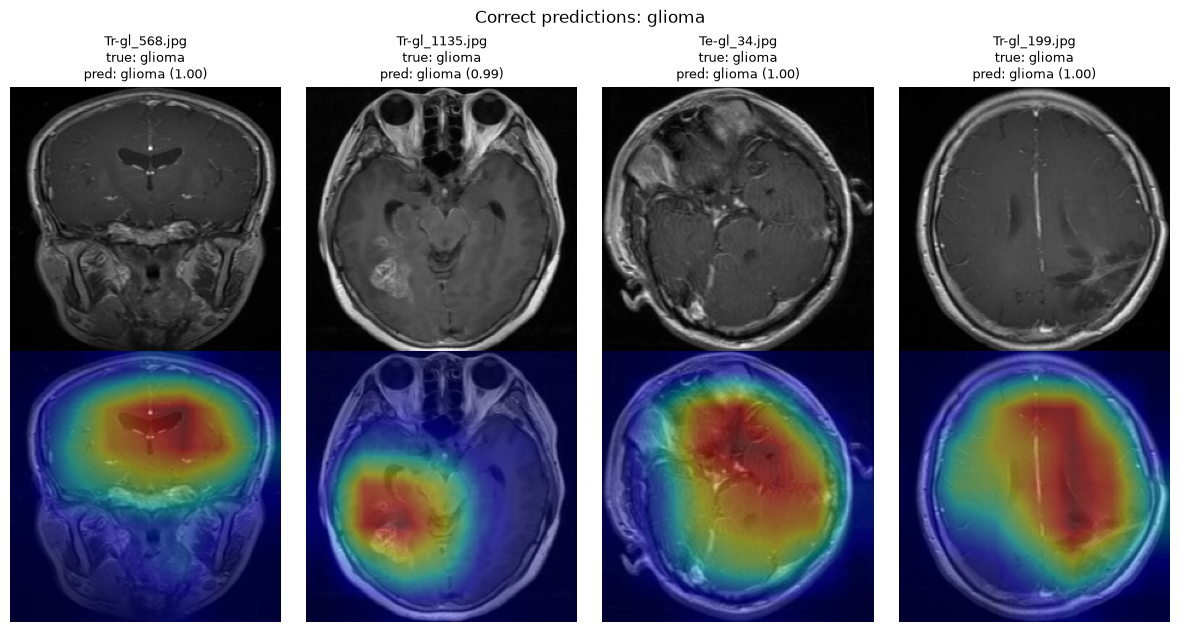

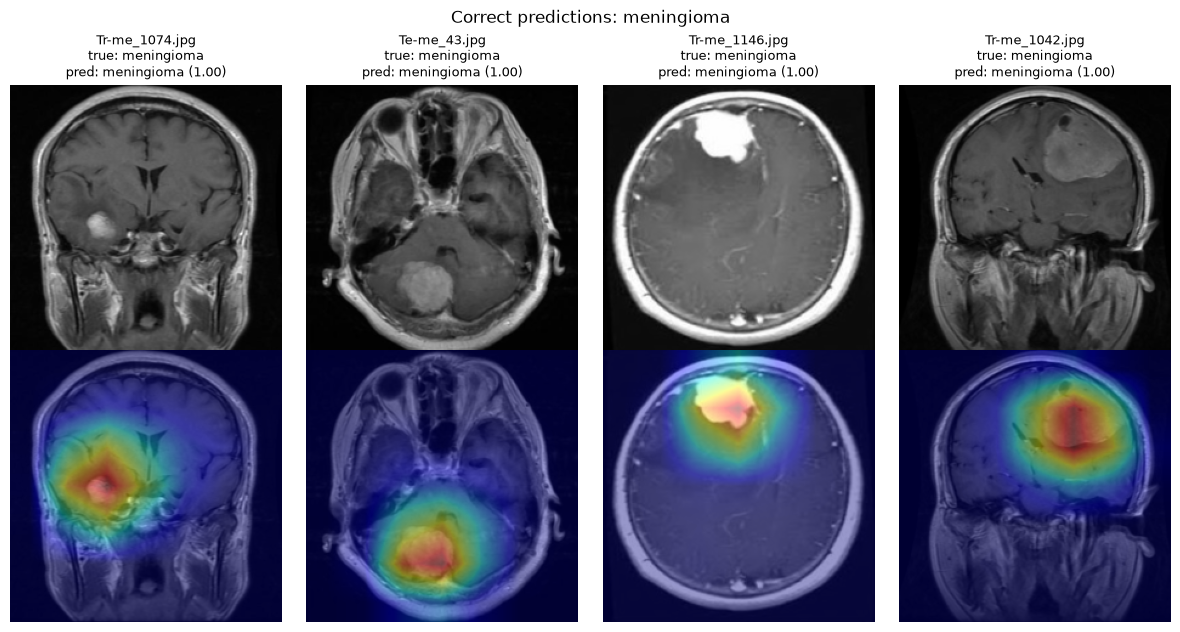

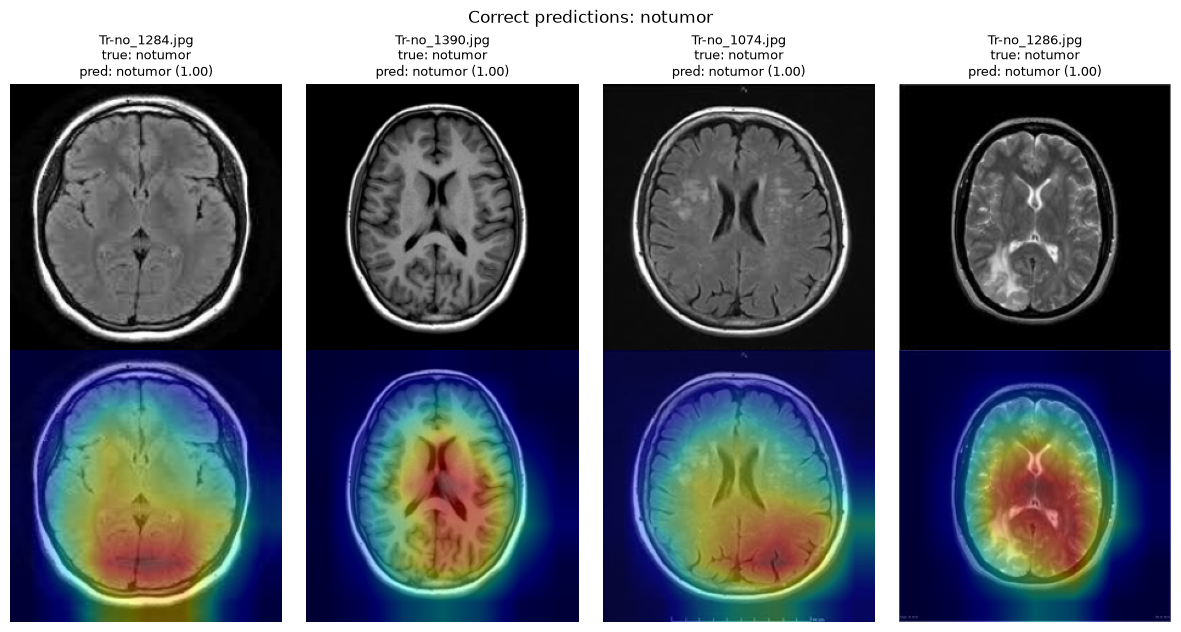

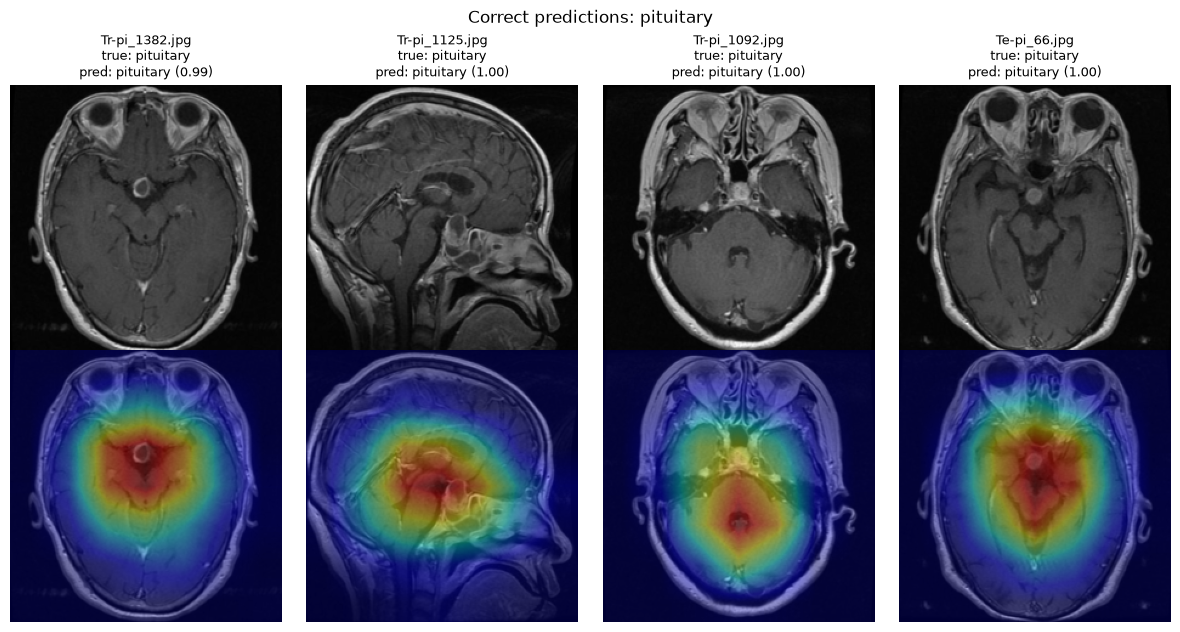

In [11]:
correct = results[results["correct"]]
sample = correct.groupby("label").sample(4, random_state=SEED)

for cls in CLASSES:
    show_gradcam(sample[sample["label"] == cls], f"Correct predictions: {cls}")

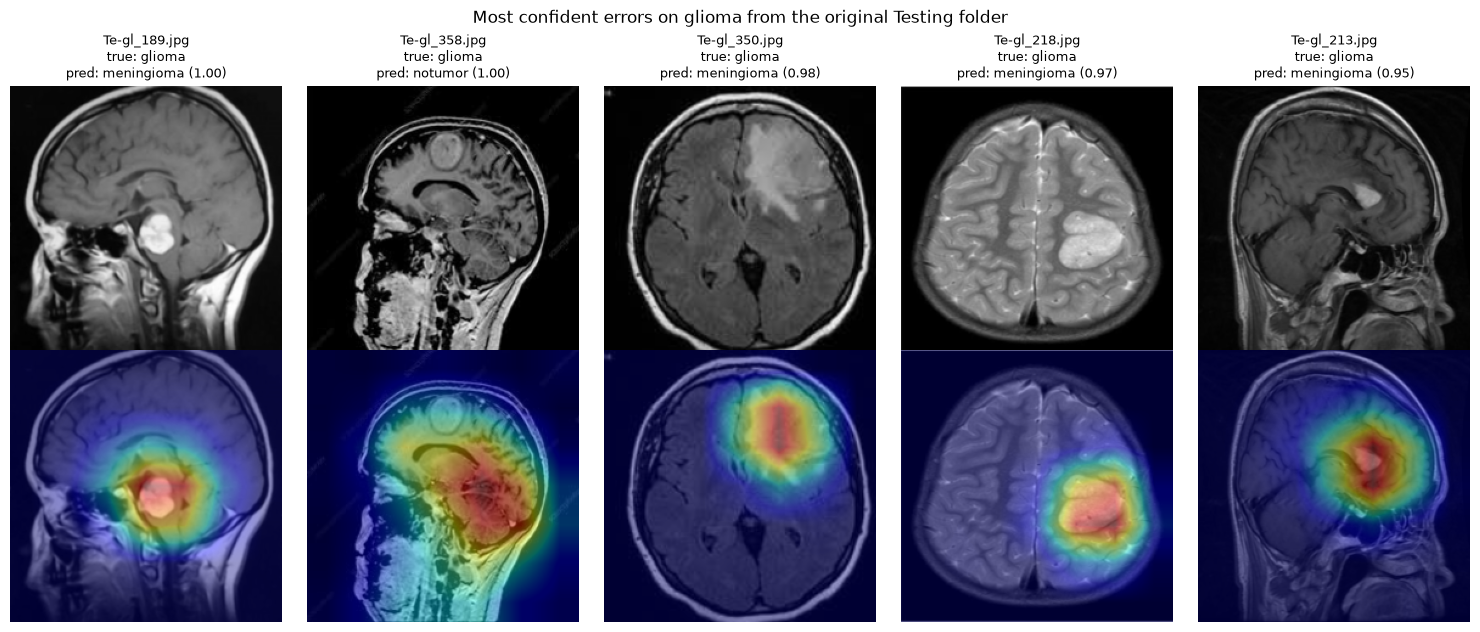

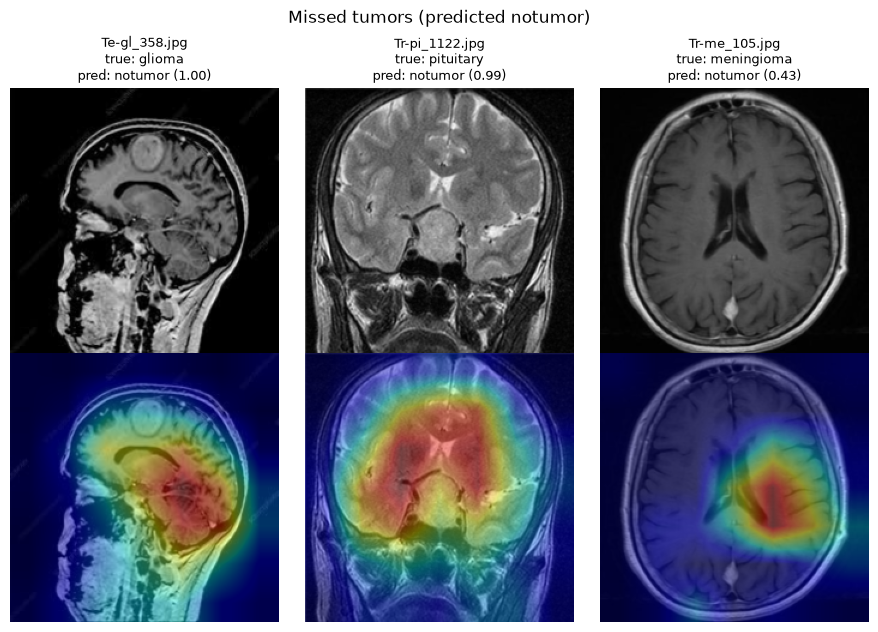

In [12]:
show_gradcam(errors[errors["path"].str.contains("Te-gl")].head(5),
             "Most confident errors on glioma from the original Testing folder")
show_gradcam(errors[errors["pred_label"] == "notumor"],
             "Missed tumors (predicted notumor)")

### Observations: Grad-CAM

- **meningioma**: heatmaps consistently on the mass (even small / posterior fossa lesions).
- **pituitary**: always central skull base (sellar region) — correct area, but the model may also use the
  slice level (orbits, brainstem) rather than the lesion alone.
- **glioma**: on the lesion or broad hemispheric regions (consistent with infiltrative tumors, less precise).
- **notumor**: diffuse, often posterior / bottom border, sometimes outside the skull → no anatomical evidence;
  compatible with **global style cues** (sequence/source bias from EDA).
- **Missed tumors**: `Tr-pi_1122` (T2) and `Te-gl_358` get notumor-like diffuse maps, not on the lesion
  → hypothesis: the model partly learned "T2/FLAIR look ≈ notumor". Per-image normalization removes global
  brightness/contrast, not sequence texture.
- **Te-gl errors**: in 4/5 the map is on the mass → the lesion is seen but read as meningioma
  (supports label noise / ambiguous cases).
- Grad-CAM is coarse (7×7) and qualitative: these are hypotheses, not proof.